# FERPA Quantitative Study | RQ2 Statistical Tests

**Research question:** How are FERPA knowledge and confidence associated with educators' scenario judgments?

**Sample:** The same **N = 100** educators used in *Fit for the Task?*, identified from the original N = 100 analysis workbook and matched to the updated Qualtrics export by Prolific ID.

**Tests implemented:** Spearman rank correlations, Mann–Whitney U, rank-biserial effect sizes, Kruskal–Wallis H, Pearson Chi-Square, and Holm corrections. All tests use the structured survey responses only. There is no analysis of written explanations.

**Important:** The RQ2 calculations do **not** measure legal correctness. They address self-assessed knowledge, confidence, training, expressed uncertainty across the nine scenarios, and responses to the **separate Q3 vignette**. Reference-aligned accuracy would require an independently approved scenario rubric.

## 1. Setup

Place the notebook and the following two files in the same directory before running all cells:

- `FERPA Survey July 24 2026 - N100 - Most Recent.xlsx`
- `FPEPG_October 26, 2026_06.13.csv`

Requires Python, NumPy, SciPy, and Matplotlib. All CSV and Excel input parsing uses Python's standard library. This notebook does not require pandas or openpyxl. The original input files are never modified.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
from collections import Counter
import csv
import math
import re
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

BASE = Path.cwd()
SAMPLE_FILE = BASE / "FERPA Survey July 24 2026 - N100 - Most Recent.xlsx"
QUALTRICS_FILE = BASE / "FPEPG_October 26, 2026_06.13.csv"
OUTPUT_DIR = BASE / "RQ2_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

SCENARIOS = [f"Scenario {i}" for i in range(1, 10)]
JUDGMENTS = {"Yes", "No", "Depends", "I do not know"}
RQ2_FIELDS = ["Prolific ID", "Q1", "Q2", "Q3", "Q6_1", "Q7_1", "Q8_1", "Q15"]
ALPHA = 0.05

for file in (SAMPLE_FILE, QUALTRICS_FILE):
    if not file.exists():
        raise FileNotFoundError(f"Missing {file.name}. Put both input files next to the notebook.")


def write_csv(filename, rows, columns):
    """Export aggregate results only, never participant identifiers."""
    with (OUTPUT_DIR / filename).open("w", encoding="utf-8-sig", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=columns)
        writer.writeheader()
        writer.writerows([{k: row.get(k, "") for k in columns} for row in rows])


def show_table(title, rows, columns):
    """Lightweight readable notebook console table without a dataframe dependency."""
    print("\n" + title)
    if not rows:
        print("No rows")
        return
    widths = {col: max(len(col), *(len(str(row.get(col, ""))) for row in rows)) for col in columns}
    print("  ".join(col.ljust(widths[col]) for col in columns))
    print("  ".join("-" * widths[col] for col in columns))
    for row in rows:
        print("  ".join(str(row.get(col, "")).ljust(widths[col]) for col in columns))


def holm_adjust(p_values):
    """Holm step-down family-wise error adjustment; same order as inputs."""
    raw = np.asarray(p_values, dtype=float)
    if np.any(~np.isfinite(raw)) or np.any((raw < 0) | (raw > 1)):
        raise ValueError("Holm correction requires valid finite p-values in [0,1].")
    m = len(raw)
    order = np.argsort(raw)
    adjusted = np.empty(m, dtype=float)
    previous = 0.0
    for rank, index in enumerate(order):
        previous = max(previous, min(1.0, (m-rank) * raw[index]))
        adjusted[index] = previous
    return adjusted


def pretty_p(p):
    return "< .001" if p < .001 else f"{p:.4f}"

print("Input files found; output folder:", OUTPUT_DIR)

Input files found; output folder: /mnt/data/RQ2_outputs


## 2. Match the original study sample and validate survey variables

The original workbook has a descriptive-question row beneath the column names and an invalid/nonresponse record. As in the RQ1 notebook, only records with a valid original Q1 answer and Prolific ID are eligible. This must yield exactly **100 distinct participants**. The updated Qualtrics export has two metadata lines after its field-name header.

The CSV repeats scenario column names for judgment and explanation. We explicitly select the **first** occurrence of each `Scenario 1` through `Scenario 9` column, which holds the categorical judgment, and ignore the explanatory text columns.

In [2]:
_NS = {"m": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}


def _excel_col_index(cell_reference):
    match = re.match(r"[A-Z]+", cell_reference)
    if not match:
        raise ValueError(f"Unexpected XLSX cell reference: {cell_reference}")
    index = 0
    for letter in match.group():
        index = index * 26 + ord(letter) - ord("A") + 1
    return index - 1


def original_sample_ids(xlsx_path):
    """Read the original N=100 roster using OOXML (zipfile + XML, standard library)."""
    with ZipFile(xlsx_path) as book:
        shared = []
        if "xl/sharedStrings.xml" in book.namelist():
            shared_root = ET.fromstring(book.read("xl/sharedStrings.xml"))
            for item in shared_root.findall("m:si", _NS):
                shared.append("".join((t.text or "") for t in item.findall(".//m:t", _NS)))
        sheet = ET.fromstring(book.read("xl/worksheets/sheet1.xml"))
        content = []
        for xml_row in sheet.findall(".//m:sheetData/m:row", _NS):
            fields = {}
            for cell in xml_row.findall("m:c", _NS):
                idx = _excel_col_index(cell.attrib["r"])
                typ = cell.attrib.get("t")
                v = cell.find("m:v", _NS)
                if typ == "s" and v is not None:
                    value = shared[int(v.text)]
                elif typ == "inlineStr":
                    value = "".join((t.text or "") for t in cell.findall(".//m:t", _NS))
                else:
                    value = v.text if v is not None else ""
                fields[idx] = str(value or "").strip()
            content.append(fields)

    if not content:
        raise ValueError("Original workbook appears empty.")
    headers = {value: col for col, value in content[0].items() if value}
    for name in ("Prolific ID", "Q1"):
        if name not in headers:
            raise ValueError(f"Original workbook missing {name} column")
    id_col, q1_col = headers["Prolific ID"], headers["Q1"]
    ids = {
        row.get(id_col, "") for row in content[1:]
        if row.get(id_col, "") and row.get(q1_col, "") in {"True", "False", "Unsure"}
    }
    if len(ids) != 100:
        raise AssertionError(f"Expected exactly 100 eligible original IDs; found {len(ids)}")
    return ids


sample_ids = original_sample_ids(SAMPLE_FILE)
records = []
with QUALTRICS_FILE.open("r", encoding="utf-8-sig", newline="") as handle:
    reader = csv.reader(handle)
    header = next(reader)
    next(reader)  # Full question wording
    next(reader)  # Qualtrics import metadata
    required = RQ2_FIELDS + SCENARIOS
    missing = [name for name in required if name not in header]
    if missing:
        raise ValueError(f"Qualtrics file missing columns: {missing}")
    # The first occurrence is the judgment, not the duplicated explanation column.
    col = {name: header.index(name) for name in required}
    for csv_row in reader:
        participant_id = csv_row[col["Prolific ID"]].strip()
        if participant_id not in sample_ids:
            continue
        rec = {name: csv_row[index].strip() for name, index in col.items()}
        records.append(rec)

participant_ids = [r["Prolific ID"] for r in records]
assert len(records) == 100 and len(set(participant_ids)) == 100, (
    "Exactly 100 unique original-study records must match in the updated Qualtrics export."
)

for row in records:
    for key, lo, hi in (("Q6_1", 0, 10), ("Q7_1", 1, 5), ("Q8_1", 1, 5)):
        try:
            number = float(row[key])
        except ValueError as exc:
            raise ValueError(f"Non-numeric {key} value in matched record") from exc
        if not lo <= number <= hi:
            raise ValueError(f"{key} outside expected scale {lo}–{hi}")
        row[key] = number
    if row["Q15"] not in ("Yes", "No"):
        raise ValueError("Unexpected or missing training (Q15) value")
    if row["Q3"] not in ("Yes", "No", "Unsure"):
        raise ValueError("Unexpected Q3 vignette judgment")
    for scenario in SCENARIOS:
        if row[scenario] not in JUDGMENTS:
            raise ValueError(f"Missing or unexpected judgment in {scenario}")

q6 = np.array([r["Q6_1"] for r in records], dtype=float)
q7 = np.array([r["Q7_1"] for r in records], dtype=float)
q8 = np.array([r["Q8_1"] for r in records], dtype=float)
training = np.array([r["Q15"] == "Yes" for r in records], dtype=bool)
q3 = np.array([r["Q3"] for r in records], dtype=object)
unknown_count = np.array([
    sum(r[s] == "I do not know" for s in SCENARIOS) for r in records
], dtype=int)

assert len(q6) == len(q7) == len(q8) == len(unknown_count) == 100
print("Matched original sample: N = 100")
print("Training: Yes =", training.sum(), "No =", (~training).sum())
print("Q3 vignette judgments:", dict(Counter(q3)))
print("Participants selecting 'I do not know' at least once:", int((unknown_count > 0).sum()))
print("Mean number of 'I do not know' scenario judgments:", round(unknown_count.mean(), 3))

Matched original sample: N = 100
Training: Yes = 52 No = 48
Q3 vignette judgments: {'No': 57, 'Yes': 24, 'Unsure': 19}
Participants selecting 'I do not know' at least once: 23
Mean number of 'I do not know' scenario judgments: 0.32


## 3. Spearman rank correlations: knowledge and confidence

Planned family of three correlations for Q6, Q7, and Q8. Holm-adjusted p-values are reported alongside unadjusted p-values. Correlations indicate association, **not legal accuracy or causation**.

In [3]:
confidence_pairs = [
    ("Q6 self-assessed knowledge vs Q7 compliance confidence", q6, q7),
    ("Q6 self-assessed knowledge vs Q8 safe-data confidence", q6, q8),
    ("Q7 compliance confidence vs Q8 safe-data confidence", q7, q8),
]
confidence_correlations = []
for name, left, right in confidence_pairs:
    result = stats.spearmanr(left, right)
    confidence_correlations.append({
        "Comparison": name, "N": len(left),
        "Spearman rho": float(result.statistic), "Unadjusted p": float(result.pvalue),
    })
for row, p_adj in zip(confidence_correlations,
                      holm_adjust([r["Unadjusted p"] for r in confidence_correlations])):
    row["Holm-adjusted p"] = float(p_adj)
    row["Significant after Holm"] = bool(p_adj < ALPHA)
show_table("Knowledge / confidence Spearman correlations", [
    {**r, "Spearman rho": f"{r['Spearman rho']:.3f}",
     "Unadjusted p": pretty_p(r["Unadjusted p"]),
     "Holm-adjusted p": pretty_p(r["Holm-adjusted p"])}
    for r in confidence_correlations
], ["Comparison", "Spearman rho", "Unadjusted p", "Holm-adjusted p", "Significant after Holm"])
write_csv("RQ2_knowledge_confidence_spearman.csv", confidence_correlations,
          ["Comparison", "N", "Spearman rho", "Unadjusted p", "Holm-adjusted p", "Significant after Holm"])


Knowledge / confidence Spearman correlations
Comparison                                              Spearman rho  Unadjusted p  Holm-adjusted p  Significant after Holm
------------------------------------------------------  ------------  ------------  ---------------  ----------------------
Q6 self-assessed knowledge vs Q7 compliance confidence  0.670         < .001        < .001           True                  
Q6 self-assessed knowledge vs Q8 safe-data confidence   0.485         < .001        < .001           True                  
Q7 compliance confidence vs Q8 safe-data confidence     0.695         < .001        < .001           True                  


## 4. Spearman correlations: confidence and expressed uncertainty

For each educator, count how many of the nine scenarios were answered **“I do not know.”** Correlate that count with Q6, Q7, and Q8. These three exploratory comparisons are treated as a **separate Holm family**. Fewer “I do not know” responses do not necessarily mean greater compliance accuracy.


Uncertainty-count Spearman correlations
Comparison                                            Spearman rho  Unadjusted p  Holm-adjusted p  Significant after Holm
----------------------------------------------------  ------------  ------------  ---------------  ----------------------
Q6 self-assessed knowledge vs count of I do not know  -0.118        0.2408        0.2408           False                 
Q7 compliance confidence vs count of I do not know    -0.294        0.0030        0.0060           True                  
Q8 safe-data confidence vs count of I do not know     -0.352        < .001        0.0010           True                  


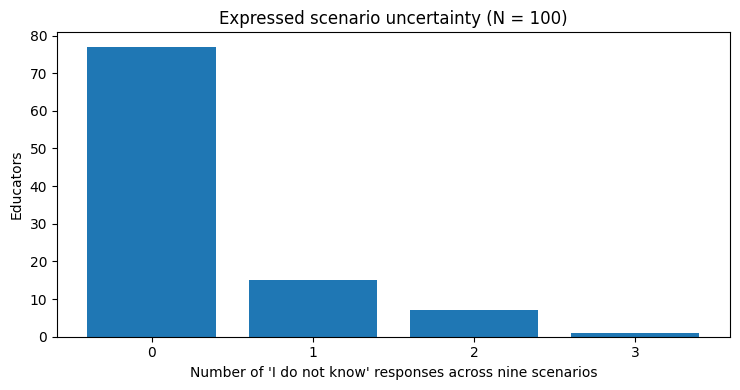

In [4]:
uncertainty_pairs = [
    ("Q6 self-assessed knowledge vs count of I do not know", q6),
    ("Q7 compliance confidence vs count of I do not know", q7),
    ("Q8 safe-data confidence vs count of I do not know", q8),
]
uncertainty_correlations = []
for name, score in uncertainty_pairs:
    result = stats.spearmanr(score, unknown_count)
    uncertainty_correlations.append({
        "Comparison": name, "N": len(score), "Spearman rho": float(result.statistic),
        "Unadjusted p": float(result.pvalue),
    })
for row, p_adj in zip(uncertainty_correlations,
                      holm_adjust([r["Unadjusted p"] for r in uncertainty_correlations])):
    row["Holm-adjusted p"] = float(p_adj)
    row["Significant after Holm"] = bool(p_adj < ALPHA)
show_table("Uncertainty-count Spearman correlations", [
    {**r, "Spearman rho": f"{r['Spearman rho']:.3f}",
     "Unadjusted p": pretty_p(r["Unadjusted p"]),
     "Holm-adjusted p": pretty_p(r["Holm-adjusted p"])}
    for r in uncertainty_correlations
], ["Comparison", "Spearman rho", "Unadjusted p", "Holm-adjusted p", "Significant after Holm"])
write_csv("RQ2_uncertainty_spearman.csv", uncertainty_correlations,
          ["Comparison", "N", "Spearman rho", "Unadjusted p", "Holm-adjusted p", "Significant after Holm"])

fig, ax = plt.subplots(figsize=(7.5, 4))
counts = Counter(unknown_count.tolist())
labels = sorted(counts)
ax.bar(labels, [counts[v] for v in labels])
ax.set(xlabel="Number of 'I do not know' responses across nine scenarios",
       ylabel="Educators", title="Expressed scenario uncertainty (N = 100)")
ax.set_xticks(labels)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "RQ2_unknown_judgment_counts.png", dpi=160)
plt.show()

## 5. Mann–Whitney U and rank-biserial effect sizes: training comparisons

Compare recent FERPA training (Q15 Yes/No) on three participant-level ordinal outcomes: Q6, Q7, and Q8. The signed rank-biserial correlation below is computed as `2U/(n_trained × n_untrained) - 1`, where U is for the **trained** group. Positive values mean trained respondents tend to have higher scores. Apply Holm across these three comparisons.


Training comparisons: Mann–Whitney U
Outcome                                  Median trained  Median untrained  Mann-Whitney U  Rank-biserial r  Unadjusted p  Holm-adjusted p  Significant after Holm
---------------------------------------  --------------  ----------------  --------------  ---------------  ------------  ---------------  ----------------------
Q6 self-assessed FERPA knowledge (0–10)  7.0             5.0               1908.0          0.529            < .001        < .001           True                  
Q7 compliance confidence (1–5)           3.5             3.0               1780.5          0.427            < .001        < .001           True                  
Q8 safe-data confidence (1–5)            4.0             3.0               1553.5          0.245            0.0272        0.0272           True                  


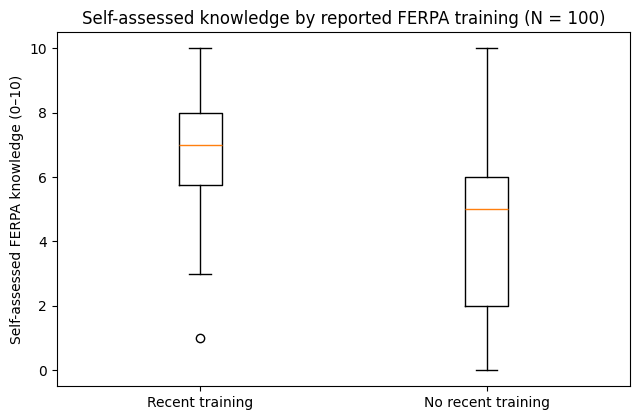

In [5]:
training_outcomes = [
    ("Q6 self-assessed FERPA knowledge (0–10)", q6),
    ("Q7 compliance confidence (1–5)", q7),
    ("Q8 safe-data confidence (1–5)", q8),
]
mann_whitney_results = []
for label, outcome in training_outcomes:
    group_yes = outcome[training]
    group_no = outcome[~training]
    test = stats.mannwhitneyu(group_yes, group_no, alternative="two-sided", method="asymptotic")
    u_stat = float(test.statistic)
    r_rank_biserial = 2 * u_stat / (len(group_yes) * len(group_no)) - 1
    mann_whitney_results.append({
        "Outcome": label,
        "N trained": len(group_yes), "N untrained": len(group_no),
        "Median trained": float(np.median(group_yes)), "Median untrained": float(np.median(group_no)),
        "Mann-Whitney U": u_stat, "Rank-biserial r": r_rank_biserial,
        "Unadjusted p": float(test.pvalue),
    })
for row, p_adj in zip(mann_whitney_results,
                      holm_adjust([r["Unadjusted p"] for r in mann_whitney_results])):
    row["Holm-adjusted p"] = float(p_adj)
    row["Significant after Holm"] = bool(p_adj < ALPHA)
show_table("Training comparisons: Mann–Whitney U", [
    {**r, "Rank-biserial r": f"{r['Rank-biserial r']:.3f}",
     "Unadjusted p": pretty_p(r["Unadjusted p"]),
     "Holm-adjusted p": pretty_p(r["Holm-adjusted p"])}
    for r in mann_whitney_results
], ["Outcome", "Median trained", "Median untrained", "Mann-Whitney U",
    "Rank-biserial r", "Unadjusted p", "Holm-adjusted p", "Significant after Holm"])
write_csv("RQ2_training_mann_whitney_rank_biserial.csv", mann_whitney_results,
          ["Outcome", "N trained", "N untrained", "Median trained", "Median untrained",
           "Mann-Whitney U", "Rank-biserial r", "Unadjusted p", "Holm-adjusted p",
           "Significant after Holm"])

fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.boxplot([q6[training], q6[~training]], tick_labels=["Recent training", "No recent training"])
ax.set(ylabel="Self-assessed FERPA knowledge (0–10)",
       title="Self-assessed knowledge by reported FERPA training (N = 100)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "RQ2_training_knowledge_boxplot.png", dpi=160)
plt.show()

## 6. Selected Kruskal–Wallis comparison: Q3 vignette groups

Compare Q6 self-assessed knowledge across the **three independent Q3 vignette response groups**: Yes, No, and Unsure. Q3 is a separate question about anonymized student assignments and vendor storage, **not one of the nine scenario columns**. This is a single exploratory test, so it is reported unadjusted. Kruskal–Wallis tests group distribution differences, not FERPA correctness.

In [6]:
q3_categories = ("Yes", "No", "Unsure")
q3_groups = [q6[q3 == choice] for choice in q3_categories]
kruskal = stats.kruskal(*q3_groups, nan_policy="raise")
kruskal_rows = [{
    "Comparison": "Q6 self-assessed knowledge by Q3 vignette judgment",
    "N": len(q6), "H statistic": float(kruskal.statistic),
    "Degrees of freedom": len(q3_categories) - 1,
    "Unadjusted p": float(kruskal.pvalue),
}]
for label, group in zip(q3_categories, q3_groups):
    print(f"Q3 = {label:<6} n={len(group):>3}  median Q6={np.median(group):.1f}")
show_table("Kruskal–Wallis result", [
    {**r, "H statistic": f"{r['H statistic']:.4f}", "Unadjusted p": pretty_p(r["Unadjusted p"])}
    for r in kruskal_rows
], ["Comparison", "H statistic", "Degrees of freedom", "Unadjusted p"])
write_csv("RQ2_kruskal_q3_knowledge.csv", kruskal_rows,
          ["Comparison", "N", "H statistic", "Degrees of freedom", "Unadjusted p"])

Q3 = Yes    n= 24  median Q6=7.0
Q3 = No     n= 57  median Q6=6.0
Q3 = Unsure n= 19  median Q6=5.0

Kruskal–Wallis result
Comparison                                          H statistic  Degrees of freedom  Unadjusted p
--------------------------------------------------  -----------  ------------------  ------------
Q6 self-assessed knowledge by Q3 vignette judgment  0.0313       2                   0.9845      


## 7. Chi-Square independence test: training vs. Q3 vignette judgment

Test whether the **Q3 vignette** judgment (Yes/No/Unsure) is associated with recent training (Q15). This is a **two-by-three** table of **independent participants**. Print observed and expected counts to assess the large-sample approximation. A significant result would indicate association, **not** that training caused better judgments.

In [7]:
observed = np.array([
    [sum((training == trained) & (q3 == choice)) for choice in q3_categories]
    for trained in (True, False)
], dtype=int)
chi2, p_chi, degrees, expected = stats.chi2_contingency(observed, correction=False)
print("Rows: Recent training / No recent training; columns: Yes / No / Unsure")
print("Observed table:\n", observed)
print("Expected counts:\n", np.round(expected, 2))
print(f"Chi-Square({degrees}) = {chi2:.4f}; p = {p_chi:.4f}")
print("Minimum expected count:", round(float(expected.min()), 2))
if (expected < 5).any():
    print("CAUTION: Sparse expected cells. Consider an exact or permutation procedure.")
else:
    print("All expected counts are at least 5.")

chi_square_rows = [{
    "Comparison": "Recent FERPA training vs Q3 vignette judgment",
    "N": len(q3), "Chi-Square": float(chi2), "Degrees of freedom": int(degrees),
    "Unadjusted p": float(p_chi), "Minimum expected count": float(expected.min()),
}]
write_csv("RQ2_chi_square_training_q3.csv", chi_square_rows,
          ["Comparison", "N", "Chi-Square", "Degrees of freedom", "Unadjusted p",
           "Minimum expected count"])

contingency_rows = []
for i, train_label in enumerate(("Recent training", "No recent training")):
    contingency_rows.extend({
        "Training group": train_label, "Q3 judgment": category,
        "Observed count": int(observed[i, j]), "Expected count": float(expected[i, j]),
    } for j, category in enumerate(q3_categories))
write_csv("RQ2_training_q3_contingency.csv", contingency_rows,
          ["Training group", "Q3 judgment", "Observed count", "Expected count"])

Rows: Recent training / No recent training; columns: Yes / No / Unsure
Observed table:
 [[10 29 13]
 [14 28  6]]
Expected counts:
 [[12.48 29.64  9.88]
 [11.52 27.36  9.12]]
Chi-Square(2) = 3.1081; p = 0.2114
Minimum expected count: 9.12
All expected counts are at least 5.


## 8. Consolidated results and interpretation safeguards

The outputs are saved as aggregate CSVs and two PNG charts in `RQ2_outputs/`. The two input datasets remain unchanged. No Prolific IDs, response texts, or person-level records are exported.

**Statistical reporting notes:**

- Holm correction is applied separately to the planned three knowledge/confidence correlations, three exploratory uncertainty correlations, and three training comparisons. The Kruskal–Wallis and Chi-Square analyses are reported as separate exploratory tests, unadjusted.
- The nine repeated scenario judgments are reduced to one **uncertainty count per educator** for the reported correlations. This respects the participant as the independent unit.
- A lower count of “I do not know” is **not** a measure of legally appropriate judgment. The Q3 vignette is separate from Scenarios 1–9.
- Without an approved expert-reference scoring rubric, this notebook does not estimate scenario accuracy or fit models predicting legal alignment.
- Test outputs are observational associations, not causal effects.

In [8]:
print("Completed all RQ2 analyses for N = 100.")
print("Results saved to:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(" -", p.name)
print("\nKey values from the matched sample:")
print("Q6/Q7 rho:", round(confidence_correlations[0]["Spearman rho"], 3))
print("Q7/Q8 rho:", round(confidence_correlations[2]["Spearman rho"], 3))
print("Trained vs untrained Q6 rank-biserial:", round(mann_whitney_results[0]["Rank-biserial r"], 3))
print("Kruskal–Wallis Q3 H:", round(kruskal_rows[0]["H statistic"], 3))
print("Chi-Square training/Q3:", round(chi_square_rows[0]["Chi-Square"], 3))

Completed all RQ2 analyses for N = 100.
Results saved to: /mnt/data/RQ2_outputs
 - RQ2_chi_square_training_q3.csv
 - RQ2_knowledge_confidence_spearman.csv
 - RQ2_kruskal_q3_knowledge.csv
 - RQ2_training_knowledge_boxplot.png
 - RQ2_training_mann_whitney_rank_biserial.csv
 - RQ2_training_q3_contingency.csv
 - RQ2_uncertainty_spearman.csv
 - RQ2_unknown_judgment_counts.png

Key values from the matched sample:
Q6/Q7 rho: 0.67
Q7/Q8 rho: 0.695
Trained vs untrained Q6 rank-biserial: 0.529
Kruskal–Wallis Q3 H: 0.031
Chi-Square training/Q3: 3.108
